In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern
from scipy.stats import norm
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')
from scipy.interpolate import griddata

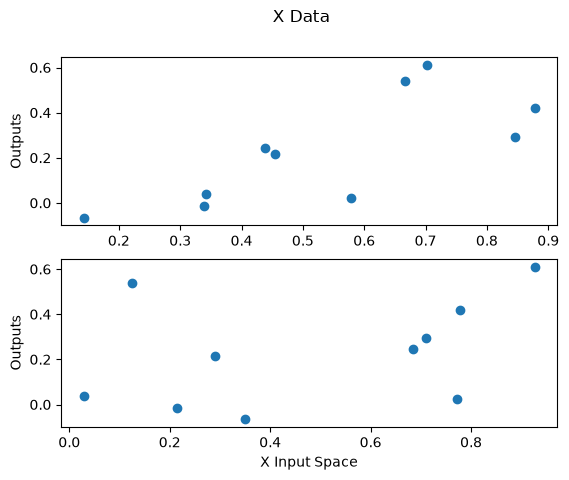

array([[0.66579958, 0.12396913],
       [0.87779099, 0.7786275 ],
       [0.14269907, 0.34900513],
       [0.84527543, 0.71112027],
       [0.45464714, 0.29045518],
       [0.57771284, 0.77197318],
       [0.43816606, 0.68501826],
       [0.34174959, 0.02869772],
       [0.33864816, 0.21386725],
       [0.70263656, 0.9265642 ]])

In [ ]:
X = np.load('..\Function_2_Data\Week_1_Data/initial_inputs.npy')
Y = np.load('..\Function_2_Data\Week_1_Data/initial_outputs.npy')

fig, (ax1, ax2) = plt.subplots(2, 1)
fig.suptitle('X Data')
ax1.scatter(X[:,0], Y)
ax1.set_ylabel('Outputs')
ax2.scatter(X[:,1], Y)
ax2.set_xlabel('X Input Space')
ax2.set_ylabel('Outputs')
plt.show()
X

In [3]:
kernel = ConstantKernel(1.0) * RBF(length_scale=[1.0, 1.0])
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6, n_restarts_optimizer=10)
gp.fit(X, Y)

,kernel,"1**2 * RBF(le..._scale=[1, 1])"
,alpha,1e-06
,optimizer,'fmin_l_bfgs_b'
,n_restarts_optimizer,10
,normalize_y,False
,copy_X_train,True
,n_targets,None
,random_state,None
,kernel__k1,1**2
,kernel__k2,"RBF(length_scale=[1, 1])"
,kernel__k1__constant_value,1.0


In [4]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    """
    Upper Confidence Bound (UCB) acquisition function.
    
    UCB = mean + kappa * std
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation
    kappa : exploration parameter (higher = more exploration)
    """
    return mu + kappa * sigma


def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei


In [5]:
def acq_objective(X):
    X = X.reshape(1, -1)
    mu, sigma = gp.predict(X, return_std=True)
               
    if acquisition == 'ei':
        acq_val = expected_improvement(mu, sigma, Y.max())
    else:
        acq_val = upper_confidence_bound(mu, sigma, kappa=0.5)
           
    return -acq_val  # Negative because we use the 'minimize' function later

In [18]:
acquisition='ei'
n_dims=X.shape[1]
bounds = [(0, 1) for _ in range(n_dims)]
best_acq = np.inf
X_next = None

for _ in range(50):  # Multiple random starts
    x0 = np.random.uniform([b[0] for b in bounds], [b[1] for b in bounds])
    result = minimize(acq_objective, x0, bounds=bounds, method='L-BFGS-B')
    if result.fun < best_acq:
        best_acq = result.fun
        X_next = result.x

In [19]:
np.set_printoptions(suppress=True, precision=6)
X_next

array([0.708951, 0.      ])

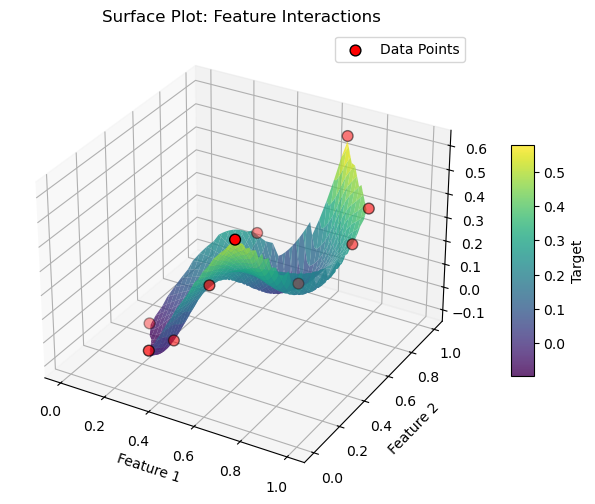

In [20]:
# **3D Surface Plot (Separate Block for Feature Interaction)**

x, y = X[:, 0], X[:, 1]
z = Y

# Create grid points for interpolation
grid_x, grid_y = np.meshgrid(
    np.linspace(0, 1, 100),
    np.linspace(0, 1, 100)
)

# Interpolate the Z values for the grid
grid_z = griddata(
    (x, y), z, 
    (grid_x, grid_y), 
    method="cubic"
)


# Plotting the surface
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(
    grid_x, grid_y, grid_z, 
    cmap="viridis", 
    edgecolor="none", 
    alpha=0.8
)
# Scatter points (data points)
ax.scatter(x, y, z, color='red', edgecolor='black', s=60, label="Data Points")
ax.legend(loc="best")  # Add legend for clarity

cb = fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10)
cb.set_label("Target")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
#     ax.set_zlabel("Target")
plt.title("Surface Plot: Feature Interactions")
plt.show()
# else:
#     print("Surface plot requires exactly 2 features in the input data.")
    
    
# The red on the 3d surface plot its just to make the plot easier to see